In [1]:
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.prebuilt import ToolNode, tools_condition

C:\Users\subha\AppData\Local\Temp\ipykernel_19160\2965980903.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
load_dotenv()

True

In [3]:
llm = ChatGoogleGenerativeAI(model= "gemini-2.5-flash", api_version='v1beta')

In [4]:
## creating a loader
loader = PyPDFLoader(r"G:\Gen AI\gen-ai\langgraph\data\intro-to-ml.pdf")
# loading the pdf
docs = loader.load()

In [5]:
len(docs)

392

In [6]:
## splitting the docs
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
## storing the splitted chunks
chunks = splitter.split_documents(documents=docs)

In [7]:
len(chunks)

973

In [8]:
chunks[:5]

[Document(metadata={'producer': '3-Heights(TM) PDF Optimization Shell 5.9.1.5 (http://www.pdf-tools.com)', 'creator': 'AH CSS Formatter V6.2 MR4 for Linux64 : 6.2.6.18551 (2014/09/24 15:00JST)', 'creationdate': '2016-09-21T13:04:39+00:00', 'author': 'Andreas C. Müller and Sarah Guido', 'title': 'Introduction to Machine Learning with Python', 'trapped': '/False', 'moddate': '2020-08-19T07:09:16+02:00', 'source': 'G:\\Gen AI\\gen-ai\\langgraph\\data\\intro-to-ml.pdf', 'total_pages': 392, 'page': 0, 'page_label': 'Cover'}, page_content='Andreas C. Müller & Sarah Guido\nIntroduction to \nMachine \nLearning  \nwith P y thon   \nA GUIDE FOR DATA SCIENTISTS'),
 Document(metadata={'producer': '3-Heights(TM) PDF Optimization Shell 5.9.1.5 (http://www.pdf-tools.com)', 'creator': 'AH CSS Formatter V6.2 MR4 for Linux64 : 6.2.6.18551 (2014/09/24 15:00JST)', 'creationdate': '2016-09-21T13:04:39+00:00', 'author': 'Andreas C. Müller and Sarah Guido', 'title': 'Introduction to Machine Learning with P

In [9]:
import os
from langchain_huggingface import HuggingFaceEmbeddings

os.environ['HF_HOME'] = r"/workspaces/gen-ai/hf_models"

embedding_model = HuggingFaceEmbeddings(
    model_name= 'sentence-transformers/all-MiniLM-L6-v2'
)

## creating a vector store
vector_store = FAISS.from_documents(chunks, embedding=embedding_model)

g:\Conda_Environment\genai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3812.06it/s]


In [10]:
vector_store

In [11]:
## creating a retriever
retriver = vector_store.as_retriever(search_type= 'similarity', search_kwargs = {'k': 4})

In [12]:
@tool
def rag_tool(query):
    """
    Retrieve relevant information from the pdf document.
    Use this tool when the user asks factual / conceptual questions
    that might be answered from the stored documents.
    """
    result = retriver.invoke(query)
    
    context = [doc.page_content for doc in result]
    metadata = [doc.metadata for doc in result]
    
    return {
        'query': query,
        'context': context,
        'metadata': metadata
    }

In [13]:
tools = [rag_tool]
llm = llm.bind_tools(tools=tools)

In [14]:
## creating graph state
class ChatState(TypedDict):
    messages : Annotated[list[BaseMessage], add_messages]

In [15]:
## defining chat node
def chat_node(state: ChatState) -> ChatState:
    messages = state['messages']
    response = llm.invoke(messages)
    return {'messages': [response]}

In [29]:
# creating graph
graph = StateGraph(ChatState)

## creating tool_node
tool_node = ToolNode(tools)

graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')

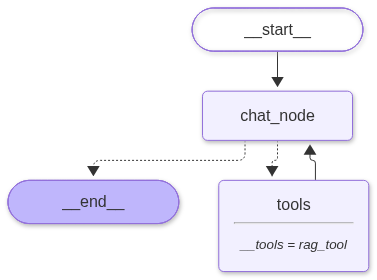

In [30]:
## compiling the graph
chatbot = graph.compile()

from IPython.display import Image
Image(chatbot.get_graph().draw_mermaid_png())

In [31]:
result = chatbot.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Using the pdf notes, explain how to find the ideal value of K in KNN. use the rag tool you have access to"
                )
            )
        ]
    }
)

In [32]:
result['messages'][-1]

AIMessage(content=[{'type': 'text', 'text': 'Based on the provided PDF notes, the document introduces the concept of `k` in k-nearest neighbors as the number of neighbors to consider for making a prediction. It mentions that `n_neighbors` is the most important parameter of `KNeighborsClassifier`. While it demonstrates how to set `n_neighbors` to 1 and evaluate the model\'s performance using the test set score, the provided snippets do not explicitly detail how to find the *ideal* value of `K`. The text indicates that "In later chapters we will discuss how we can improve performance, and what caveats there are in tuning a model" and "We will go into more detail about this in Chapter 2; for now, we’ll use only a single neighbor." This suggests that the method for finding the ideal `K` is covered in subsequent sections of the document not included in the current context.', 'extras': {'signature': 'CvYGAWkUfRNW1MEt+GciSFNSmX9Q+RNdmjOchApDcjxhPdklGAMbDtwEUrRDKswMrTBe/K3GU/GOosUzhgqRi4aSkO49